# FFM_3_0 — capacity stress test

**这个 notebook 不是为了拿更高的分数。** 它是一个诊断实验，回答一个问题：

> landmark→latent 学不动，是**模型不够强 / 训练不够久**，还是**19 个 landmark 本身
> 信息不足**？

## 事先约定（跑之前写死，跑完不许改）

1. **报的数是 epoch 5000 那一个。** 7 个 checkpoint 是画曲线用的诊断，
   **绝不允许**在 5000 个 epoch 里挑最漂亮的 validation 分数当结果 —— 那是
   看了 5000 次然后取最大值，噪声也能挑出正数。
2. **只改训练时长和输入编码。** hidden / layers / dropout / lr / wd / batch
   全部沿用 FFM_2_9 的值，否则结果变化归因不了。
3. **σ 和 M 用 2_9 内层 CV 选出来的那一组**（对模型最有利的一组）。
   故意用差的 σ 得到差的结果没有说服力。
4. **test 的 15 个人这里一次都不碰。** 全部在开发集 46 人内部做。

## 四个实验

| | 内容 | 排除的反驳 |
|---|---|---|
| **A** | Raw XYZ + Ridge | — 建立弱信号的存在 |
| **B** | Raw + per-landmark RFF + Ridge | "是不是特征表示不够" |
| **C** | Raw + RFF + MLP，**5000 epochs**，含 shuffled-Y 对照 | "是不是训练太短 / 容量不够" |
| **D** | M = 32 → 512（ridge） | "是不是 Fourier 基太少" |
| **E** | **CV-R² vs 训练人数**（ridge） | "是不是人太少" ← 这个才是真问题 |

## ★ 关于 "train R² → 1 证明容量够" 这个论证

**它比看上去弱得多。** D = P·2M + 3P = 1273，训练集只有 41 人。
`D > N` 时**一个普通最小二乘就能把训练集插值到 R²=1**，不需要任何"容量"。
所以 train R² → 1 几乎是维度的必然，不是网络强的证据。Cell 4 里放了这个
反例（α→0 的线性回归，train R²=1）。

真正让这个论证成立的是 **Cell 5 的 shuffled-Y 对照**：如果把 y 打乱、
网络照样把训练集背到 R²≈1 而 CV 停在 0，那就说明 train R² 不携带任何
关于"有没有信号"的信息 —— 有说服力的是**真实 CV 曲线和打乱 CV 曲线
重合**这件事，不是 train R² 本身。

写给导师的那句话要用 **suggests**，不是 proves。


In [ ]:
# ==========================================================================
# Cell 0 — 载入 FFM_2_8 的缓存（和 FFM_2_9 完全一样）
# ==========================================================================
import os, sys, json, time, hashlib, warnings
warnings.filterwarnings('ignore')
import numpy as np

IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    DRIVE = '/content/drive/MyDrive'
else:
    DRIVE = os.environ.get('ELEC5021_DRIVE', os.path.expanduser('~/Documents/26S2/ELEC5021'))

SAVE_DIR = f'{DRIVE}/HRTF_Checkpoints'
CACHE    = f'{SAVE_DIR}/landmark2z_v28_cache.npz'
assert os.path.exists(CACHE), f'找不到 {CACHE} —— 先跑 FFM_2_8 的最后一格'

d = np.load(CACHE, allow_pickle=True)
XYZ_SUB = d['xyz_sub'].astype(np.float64)          # (N, P, 3) mm
Z_SUB   = d['Z_sub'].astype(np.float64)            # (N, 5952)
SYM, AE_PART = d['sym'], d['ae_part']
N, P, _ = XYZ_SUB.shape
n_bins, LATENT_DIM = int(d['n_bins']), int(d['latent_dim'])
SUBJ_HASH = str(d['subject_hash'])

print(f'缓存 <- {CACHE}')
print(f'  xyz_sub {XYZ_SUB.shape} {d["coord_unit"]} | Z_sub {Z_SUB.shape}')
print(f'  N={N} | P={P} | hash {SUBJ_HASH} | ckpt {d["ckpt"]}')
print(f'  side {float(d["side_frac"]):.1%} 投影={bool(d["side_projected"])}')
print(f'\n2_8: dCor²ᵤ = {float(d["dcor_obs"]):+.4f}, p = {float(d["dcor_p"]):.4f}')


Mounted at /content/drive
缓存 <- /content/drive/MyDrive/HRTF_Checkpoints/landmark2z_v28_cache.npz
  xyz_sub (61, 19, 3) mm | Z_sub (61, 5952)
  N=61 | P=19 | hash 5d151b755ad8 | ckpt FFM26_best.pth
  side 0.2% 投影=False

2_8: dCor²ᵤ = +0.0710, p = 0.0020


In [ ]:
# ==========================================================================
# Cell 1 — ★ 配置（事先约定，跑完不许改）
# ==========================================================================
CFG = dict(
    # ---- 坐标（与 2_9 相同）----
    COORD_CENTER = 'subject_centroid',
    COORD_UNIT   = 'm',

    # ---- ★ 编码：用 2_9 内层 CV 选出来的那一组，即对模型最有利的一组 ----
    RFF_M        = 32,
    RFF_SIGMA    = 20.0,        # 米制。2_9 的 σ 网格 [20,50,100,200,500] 选中下界
    INCLUDE_RAW  = True,        # ★ [raw XYZ, RFF] 拼接 —— 不让人说 Fourier 破坏了原始坐标

    # ---- 目标 ----
    K_VAR = 0.95,

    # ---- MLP：★ 除了 EPOCHS，全部沿用 FFM_2_9 ----
    HIDDEN = 128, N_LAYERS = 2, DROPOUT = 0.2,
    LR = 1e-3, WEIGHT_DECAY = 1e-2, BATCH = 8,
    EPOCHS = 5000,                                   # ← 唯一改动
    CKPTS  = [50, 100, 200, 500, 1000, 2000, 5000],  # 记录点，不是选择点

    # ---- 评估 ----
    N_FOLDS = 10, N_SEEDS = 1, SEED = 0,

    # ---- 诊断 D / E ----
    M_SWEEP   = [8, 16, 32, 64, 128, 256, 512],
    N_CURVE   = [8, 12, 16, 20, 24, 28, 31],
    N_REPEATS = 20,
)
ALPHAS = [1e-1, 1., 10., 1e2, 1e3, 1e4, 1e5]

# ★ 事先约定的报数点。改这一行就等于事后选择。
REPORT_EPOCH = CFG['EPOCHS']
assert REPORT_EPOCH in CFG['CKPTS']

print(json.dumps(CFG, indent=1, default=str))
D_in = P * (2 * CFG['RFF_M'] + (3 if CFG['INCLUDE_RAW'] else 0))
print(f"\n输入维度 D = P·(2M+3) = {D_in}   训练集 41 人")
print(f'★ D/N = {D_in/41:.0f}。D > N，所以线性最小二乘就能把训练集插值到 R²=1，'
      '\n  train R² 接近 1 是维度的必然，不是「容量够」的证据。Cell 4 有反例。')


{
 "COORD_CENTER": "subject_centroid",
 "COORD_UNIT": "m",
 "RFF_M": 32,
 "RFF_SIGMA": 20.0,
 "INCLUDE_RAW": true,
 "K_VAR": 0.95,
 "HIDDEN": 128,
 "N_LAYERS": 2,
 "DROPOUT": 0.2,
 "LR": 0.001,
 "WEIGHT_DECAY": 0.01,
 "BATCH": 8,
 "EPOCHS": 5000,
 "CKPTS": [
  50,
  100,
  200,
  500,
  1000,
  2000,
  5000
 ],
 "N_FOLDS": 10,
 "N_SEEDS": 1,
 "SEED": 0,
 "M_SWEEP": [
  8,
  16,
  32,
  64,
  128,
  256,
  512
 ],
 "N_CURVE": [
  8,
  12,
  16,
  20,
  24,
  28,
  31
 ],
 "N_REPEATS": 20
}

输入维度 D = P·(2M+3) = 1273   训练集 41 人
★ D/N = 31。D > N，所以线性最小二乘就能把训练集插值到 R²=1，
  train R² 接近 1 是维度的必然，不是「容量够」的证据。Cell 4 有反例。


In [ ]:
# ==========================================================================
# Cell 2 — 坐标预处理 · RFF（与 FFM_2_9 逐字相同的构造）
#
# ★ B 是固定随机特征，register_buffer 存进 state_dict。
# ==========================================================================
import torch, torch.nn as nn

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('device:', DEVICE)


def preprocess_coords(xyz, center, unit):
    X = xyz.copy()
    if center == 'subject_centroid': X = X - X.mean(1, keepdims=True)
    elif center != 'none': raise ValueError(center)
    if unit == 'm': X = X / 1000.0
    elif unit != 'mm': raise ValueError(unit)
    return X


class PerLandmarkFourierFeatures(nn.Module):
    """γ(p_i) = [sin(2πB p_i), cos(2πB p_i)]，B ∈ R^(M×3)，所有 landmark 共享。"""
    def __init__(self, M, sigma, seed, include_raw=False):
        super().__init__()
        self.M, self.include_raw = M, include_raw
        B = np.random.default_rng(seed).normal(0.0, sigma, size=(M, 3))
        self.register_buffer('B', torch.tensor(B, dtype=torch.float64))

    def forward(self, xyz):
        assert xyz.ndim == 3 and xyz.shape[-1] == 3
        phase = 2 * np.pi * (xyz @ self.B.T)
        f = torch.cat([torch.sin(phase), torch.cos(phase)], dim=-1)
        if self.include_raw:
            f = torch.cat([xyz, f], dim=-1)
        return f.reshape(len(xyz), -1)


def encode(xyz_np, M, sigma, seed=0, include_raw=True):
    X = torch.tensor(xyz_np, dtype=torch.float64)
    with torch.no_grad():
        return PerLandmarkFourierFeatures(M, sigma, seed, include_raw)(X).numpy()


XYZ = preprocess_coords(XYZ_SUB, CFG['COORD_CENTER'], CFG['COORD_UNIT'])
X_RAW = XYZ.reshape(N, -1)                                  # (N, 3P)
X_RFF = encode(XYZ, CFG['RFF_M'], CFG['RFF_SIGMA'], CFG['SEED'], True)   # [raw, RFF]
print(f'X_RAW {X_RAW.shape} | X_RFF(含 raw) {X_RFF.shape}')

# ---- σ 的物理尺度（★ 口径：λ = 1/median‖b‖，和 2_9 Cell 2 同一个定义）----
_B = np.random.default_rng(CFG['SEED']).normal(0, CFG['RFF_SIGMA'], size=(4096, 3))
_lam = 1000.0 / np.median(np.linalg.norm(_B, axis=1))
print(f"σ={CFG['RFF_SIGMA']:g} -> median‖b‖={np.median(np.linalg.norm(_B,axis=1)):.1f}, "
      f'λ≈{_lam:.1f} mm')
print('★ 注意 λ = 1/median‖b‖ ≈ 1/(1.54σ)，不是 1/σ。三维高斯的模长中位数是 1.54σ。')
print(f'  λ≈{_lam:.0f} mm 落在头尺寸一侧，不在耳廓的 5–10 mm。这一点写结论时要说。')


device: cuda
X_RAW (61, 57) | X_RFF(含 raw) (61, 1273)
σ=20 -> median‖b‖=30.8, λ≈32.5 mm
★ 注意 λ = 1/median‖b‖ ≈ 1/(1.54σ)，不是 1/σ。三维高斯的模长中位数是 1.54σ。
  λ≈32 mm 落在头尺寸一侧，不在耳廓的 5–10 mm。这一点写结论时要说。


In [ ]:
# ==========================================================================
# Cell 3 — 划分 · fold-local 目标 · 完整性哨兵
# ==========================================================================
from sklearn.model_selection import KFold
from sklearn.linear_model import Ridge

I_TR = np.where(AE_PART == 'train')[0]
I_VA = np.where(AE_PART == 'val')[0]
I_TE = np.where(AE_PART == 'test')[0]
assert not (set(I_TR.tolist()) & set(I_VA.tolist()))
assert not ((set(I_TR.tolist()) | set(I_VA.tolist())) & set(I_TE.tolist()))
DEV = np.concatenate([I_TR, I_VA])
print(f'train {len(I_TR)} | val {len(I_VA)} | test {len(I_TE)}  ->  开发集 {len(DEV)} 人')
print('★ test 的 15 人在这个 notebook 里一次都不出现。')

Z_FINGERPRINT = hashlib.md5(np.ascontiguousarray(Z_SUB)).hexdigest()[:12]
def assert_Z_clean():
    h = hashlib.md5(np.ascontiguousarray(Z_SUB)).hexdigest()[:12]
    assert h == Z_FINGERPRINT, f'★ Z_SUB 被改动 ({h} != {Z_FINGERPRINT})，重跑 Cell 0'


def make_target(idx_fit, Z=None, k_var=None):
    """★ PCA/均值只用训练折。Z 可传入打乱版本（负对照用）。"""
    Z = Z_SUB if Z is None else Z
    k_var = k_var or CFG['K_VAR']
    mu = Z[idx_fit].mean(0)
    U, S, Vt = np.linalg.svd(Z[idx_fit] - mu, full_matrices=False)
    K = int(np.searchsorted(np.cumsum(S**2) / (S**2).sum(), k_var) + 1)
    Pm = Vt[:K]
    return (lambda Zr: (Zr - mu) @ Pm.T), (lambda Y: Y @ Pm + mu), K


def r2_score(Y_true, Y_pred, Y_train_mean):
    """基线 = 训练折的目标均值 -> 常数预测器恰好给 0。"""
    return 1 - ((Y_true - Y_pred)**2).sum() / ((Y_true - Y_train_mean)**2).sum()


def standardize(X_fit, X_apply):
    mu, sd = X_fit.mean(0), X_fit.std(0) + 1e-12
    return (X_fit - mu) / sd, [(x - mu) / sd for x in X_apply]


_yt = np.random.default_rng(0).normal(size=(20, 4))
_ye = np.random.default_rng(1).normal(size=(7, 4))
assert abs(r2_score(_ye, np.tile(_yt.mean(0), (7, 1)), _yt.mean(0))) < 1e-12
print('r2_score 零点校准通过（常数预测器 = 0）')
_, _, K_dev = make_target(DEV)
print(f'开发集上 {CFG["K_VAR"]:.0%} 方差需 K = {K_dev} 维（每折各自重算）')


train 37 | val 9 | test 15  ->  开发集 46 人
★ test 的 15 人在这个 notebook 里一次都不出现。
r2_score 零点校准通过（常数预测器 = 0）
开发集上 95% 方差需 K = 37 维（每折各自重算）


In [ ]:
# ==========================================================================
# Cell 4 — 实验 A / B（ridge），外加「D>N 就能插值」的反例
# ==========================================================================
assert_Z_clean()

def cv_ridge(X_all, alpha, idx, folds, Z=None, seed=None):
    kf = KFold(folds, shuffle=True, random_state=CFG['SEED'] if seed is None else seed)
    te, tr = [], []
    for a, b in kf.split(idx):
        i_tr, i_te = idx[a], idx[b]
        fwd, _, _ = make_target(i_tr, Z)
        Zm = Z_SUB if Z is None else Z
        Y_tr, Y_te = fwd(Zm[i_tr]), fwd(Zm[i_te])
        Xtr, (Xte,) = standardize(X_all[i_tr], [X_all[i_te]])
        m = Ridge(alpha=alpha).fit(Xtr, Y_tr)
        te.append(r2_score(Y_te, m.predict(Xte), Y_tr.mean(0)))
        tr.append(r2_score(Y_tr, m.predict(Xtr), Y_tr.mean(0)))
    return np.asarray(te), np.asarray(tr)


def select_ridge(X_all, idx, Z=None, tag=''):
    best = (-9e9, None)
    for al in ALPHAS:
        sc, _ = cv_ridge(X_all, al, idx, 5, Z)
        if sc.mean() > best[0]: best = (sc.mean(), al)
    te, tr = cv_ridge(X_all, best[1], idx, CFG['N_FOLDS'], Z)
    if tag:
        print(f'{tag:<34}CV-R² {te.mean():+.4f} ± {te.std(ddof=1)/np.sqrt(len(te)):.4f} | '
              f'train {tr.mean():+.4f} | D={X_all.shape[1]:>5} | α={best[1]:g}')
    return dict(tag=tag, cv=float(te.mean()), sem=float(te.std(ddof=1)/np.sqrt(len(te))),
                train=float(tr.mean()), alpha=best[1], D=int(X_all.shape[1]), folds=te)

print(f"{'':34}{'':>18}{'':>16}\n实验 A / B —— 内层 5 折选 α，外层 {CFG['N_FOLDS']} 折报分\n")
EXP_A = select_ridge(X_RAW, DEV, tag='A  Raw XYZ + Ridge')
EXP_B = select_ridge(X_RFF, DEV, tag='B  Raw + per-landmark RFF + Ridge')

# ---- 反例：α→0 的线性回归，train R² 会到 1 ----
te0, tr0 = cv_ridge(X_RFF, 1e-10, DEV, CFG['N_FOLDS'])
print(f'\n★ 反例  Raw+RFF + Ridge(α→0)        CV-R² {te0.mean():+.4f} | '
      f'train {tr0.mean():+.4f}')
print(f'  D={X_RFF.shape[1]} > 每折训练 {int(len(DEV)*0.9)} 人，'
      '一个线性模型就能把训练集插值到 R²≈1。')
print('  ★ 所以「MLP 的 train R² 接近 1」本身不构成「容量足够」的证据 ——')
print('    有信息量的是 Cell 5 里【真实 CV 曲线】和【打乱 CV 曲线】的关系。')


                                                                    
实验 A / B —— 内层 5 折选 α，外层 10 折报分

A  Raw XYZ + Ridge                CV-R² +0.0762 ± 0.0138 | train +0.1268 | D=   57 | α=1000
B  Raw + per-landmark RFF + Ridge CV-R² +0.0845 ± 0.0155 | train +0.2270 | D= 1273 | α=10000

★ 反例  Raw+RFF + Ridge(α→0)        CV-R² -1.3063 | train +1.0000
  D=1273 > 每折训练 41 人，一个线性模型就能把训练集插值到 R²≈1。
  ★ 所以「MLP 的 train R² 接近 1」本身不构成「容量足够」的证据 ——
    有信息量的是 Cell 5 里【真实 CV 曲线】和【打乱 CV 曲线】的关系。


In [ ]:
# ==========================================================================
# Cell 5 — ★ 实验 C：Raw + RFF + MLP，5000 epochs
#
# 两条腿一起跑：
#   real     —— 真实目标
#   shuffled —— 目标按人打乱（同样的网络、同样的 5000 epoch）
# 如果两条 train 曲线都爬到 ≈1 而两条 CV 曲线都贴着 0，
# 那么 train R² 不携带任何关于「有没有信号」的信息。
#
# ★ 报的是 epoch 5000。中间 6 个点只用来画曲线，不许挑。
# ==========================================================================
assert_Z_clean()

def run_curve(X_all, i_tr, i_te, seed, Z=None):
    """训练一个网络到 EPOCHS，在 CKPTS 上记录 (train R², CV R²)。"""
    torch.manual_seed(seed); np.random.seed(seed)
    Zm = Z_SUB if Z is None else Z
    fwd, _, K = make_target(i_tr, Z)
    Y_tr, Y_te = fwd(Zm[i_tr]), fwd(Zm[i_te])
    Xtr, (Xte,) = standardize(X_all[i_tr], [X_all[i_te]])
    Xt = torch.tensor(Xtr, dtype=torch.float32, device=DEVICE)
    Yt = torch.tensor(Y_tr, dtype=torch.float32, device=DEVICE)
    Xv = torch.tensor(Xte, dtype=torch.float32, device=DEVICE)

    layers, dc = [], Xt.shape[1]
    for _ in range(CFG['N_LAYERS']):
        layers += [nn.Linear(dc, CFG['HIDDEN']), nn.GELU(), nn.Dropout(CFG['DROPOUT'])]
        dc = CFG['HIDDEN']
    layers += [nn.Linear(dc, K)]
    net = nn.Sequential(*layers).to(DEVICE)
    opt = torch.optim.AdamW(net.parameters(), lr=CFG['LR'],
                            weight_decay=CFG['WEIGHT_DECAY'])
    n, bs = len(Xt), CFG['BATCH']
    ymean = Y_tr.mean(0)
    out = {}
    for ep in range(1, CFG['EPOCHS'] + 1):
        net.train()
        perm = torch.randperm(n, device=DEVICE)
        for k in range(0, n, bs):
            j = perm[k:k+bs]
            opt.zero_grad()
            nn.functional.mse_loss(net(Xt[j]), Yt[j]).backward()
            opt.step()
        if ep in CKSET:
            net.eval()
            with torch.no_grad():
                pt, pv = net(Xt).cpu().numpy(), net(Xv).cpu().numpy()
            out[ep] = (r2_score(Y_tr, pt, ymean), r2_score(Y_te, pv, ymean))
    n_par = sum(p.numel() for p in net.parameters())
    return out, n_par


CKSET = set(CFG['CKPTS'])

def stress(Z=None, label='real'):
    """N_SEEDS x N_FOLDS 条曲线，返回 {epoch: (train 向量, cv 向量)}"""
    acc = {e: ([], []) for e in CFG['CKPTS']}
    npar = 0
    t0 = time.time()
    for sd in range(CFG['N_SEEDS']):
        kf = KFold(CFG['N_FOLDS'], shuffle=True, random_state=CFG['SEED'] + sd)
        for fi, (a, b) in enumerate(kf.split(DEV)):
            o, npar = run_curve(X_RFF, DEV[a], DEV[b], sd, Z)
            for e, (tr, te) in o.items():
                acc[e][0].append(tr); acc[e][1].append(te)
            print(f'\r  {label}  seed {sd} fold {fi+1}/{CFG["N_FOLDS"]}  '
                  f'{time.time()-t0:6.0f}s', end='')
    print()
    return {e: (np.array(v[0]), np.array(v[1])) for e, v in acc.items()}, npar


_runs = 2 * CFG['N_SEEDS'] * CFG['N_FOLDS']
print(f"实验 C —— {_runs} 次训练 x {CFG['EPOCHS']} epoch")
print(f'⚠️ CPU 上约 {_runs*100/60:.0f} 分钟，GPU 上快得多。'
      f"想先试通就把 N_SEEDS 或 N_FOLDS 调小。\n")

CURVE_REAL, NPAR = stress(None, 'real    ')
Z_SHUF = Z_SUB[np.random.default_rng(1234).permutation(N)]
CURVE_SHUF, _ = stress(Z_SHUF, 'shuffled')
assert_Z_clean()

print(f'\n参数量 {NPAR/1e3:.0f}k = {NPAR/len(I_TR):.0f}/训练被试\n')
print(f"{'epoch':>7}{'train R² 真':>13}{'CV R² 真':>12}{'train R² 打乱':>15}{'CV R² 打乱':>13}")
print('-' * 61)
for e in CFG['CKPTS']:
    a, b = CURVE_REAL[e]; c, f = CURVE_SHUF[e]
    mark = '  <- 报这个' if e == REPORT_EPOCH else ''
    print(f'{e:>7}{a.mean():>13.4f}{b.mean():>12.4f}{c.mean():>15.4f}{f.mean():>13.4f}{mark}')
print('-' * 61)


实验 C —— 20 次训练 x 5000 epoch
⚠️ CPU 上约 33 分钟，GPU 上快得多。想先试通就把 N_SEEDS 或 N_FOLDS 调小。

  real      seed 0 fold 10/10     140s
  shuffled  seed 0 fold 10/10     141s

参数量 184k = 4972/训练被试

  epoch   train R² 真     CV R² 真    train R² 打乱     CV R² 打乱
-------------------------------------------------------------
     50       0.5176     -0.0642         0.5353      -0.4205
    100       0.7455     -0.1946         0.7415      -0.5236
    200       0.9114     -0.2031         0.9114      -0.5436
    500       0.9773     -0.1445         0.9782      -0.4178
   1000       0.9843     -0.0821         0.9830      -0.2978
   2000       0.9889     -0.0265         0.9887      -0.2060
   5000       0.9895      0.0078         0.9880      -0.1080  <- 报这个
-------------------------------------------------------------


In [ ]:
# ==========================================================================
# Cell 5b — 实验 C 的判读（★ 只看 epoch 5000）
# ==========================================================================
tr_r, cv_r = CURVE_REAL[REPORT_EPOCH]
tr_s, cv_s = CURVE_SHUF[REPORT_EPOCH]
sem = lambda v: v.std(ddof=1) / np.sqrt(len(v))

print(f'epoch {REPORT_EPOCH}（事先约定的报数点，n={len(cv_r)} 折）')
print(f'  真实    train {tr_r.mean():+.4f}   CV {cv_r.mean():+.4f} ± {sem(cv_r):.4f}')
print(f'  打乱    train {tr_s.mean():+.4f}   CV {cv_s.mean():+.4f} ± {sem(cv_s):.4f}')

d_cv = cv_r - cv_s
print(f'\n真实 CV − 打乱 CV = {d_cv.mean():+.4f} ± {d_cv.std(ddof=1)/np.sqrt(len(d_cv)):.4f}'
      f'  （配对，同一批折）')

print('\n判读：')
if tr_s.mean() > 0.9:
    print(f'  · 打乱后 train R² 仍到 {tr_s.mean():.3f} —— 网络能把纯噪声背下来。')
    print('    => 「train R² 接近 1」不构成「学到了东西」的证据，这一条论证作废。')
if cv_r.mean() <= 0.02:
    print(f'  · 真实 CV R² = {cv_r.mean():+.4f} ≤ 0.02，训练 {REPORT_EPOCH} epoch 之后仍然如此。')
    print('    => 排除「训练太短」。')
_best_e = max(CFG['CKPTS'], key=lambda e: CURVE_REAL[e][1].mean())
print(f'  · 顺带一提：{len(CFG["CKPTS"])} 个 checkpoint 里 CV 最高的是 epoch {_best_e} '
      f'({CURVE_REAL[_best_e][1].mean():+.4f}，epoch {REPORT_EPOCH} 是 {cv_r.mean():+.4f}）。')
print(f'    ★ 这个数【不能报】—— 它是 {len(CFG["CKPTS"])} 次观测的最大值，不是一次测量。')
print('\n★ 这个实验排除的是「优化不足」和「训练时长不足」，')
print('  它【不能】排除「换一种 architecture 就行」。措辞用 suggests，不用 proves。')


epoch 5000（事先约定的报数点，n=10 折）
  真实    train +0.9895   CV +0.0078 ± 0.0200
  打乱    train +0.9880   CV -0.1080 ± 0.0257

真实 CV − 打乱 CV = +0.1158 ± 0.0285  （配对，同一批折）

判读：
  · 打乱后 train R² 仍到 0.988 —— 网络能把纯噪声背下来。
    => 「train R² 接近 1」不构成「学到了东西」的证据，这一条论证作废。
  · 真实 CV R² = +0.0078 ≤ 0.02，训练 5000 epoch 之后仍然如此。
    => 排除「训练太短」。
  · 顺带一提：7 个 checkpoint 里 CV 最高的是 epoch 5000 (+0.0078，epoch 5000 是 +0.0078）。
    ★ 这个数【不能报】—— 它是 7 次观测的最大值，不是一次测量。

★ 这个实验排除的是「优化不足」和「训练时长不足」，
  它【不能】排除「换一种 architecture 就行」。措辞用 suggests，不用 proves。


In [ ]:
# ==========================================================================
# Cell 6 — 诊断 D：Fourier 基的数量 M = 8 … 512（ridge，闭式，无 SGD 噪声）
#
# 排除的反驳：「M=32 太少」。
# ==========================================================================
assert_Z_clean()
print(f"{'M':>6}{'D':>8}{'CV-R²':>10}{'±SEM':>8}{'train':>9}{'α':>10}")
print('-' * 51)
SWEEP_M = []
for M in CFG['M_SWEEP']:
    Xm = encode(XYZ, M, CFG['RFF_SIGMA'], CFG['SEED'], CFG['INCLUDE_RAW'])
    r = select_ridge(Xm, DEV)
    SWEEP_M.append(dict(M=M, **{k: r[k] for k in ('cv', 'sem', 'train', 'alpha', 'D')}))
    print(f"{M:>6}{r['D']:>8}{r['cv']:>+10.4f}{r['sem']:>8.4f}"
          f"{r['train']:>+9.4f}{r['alpha']:>10.4g}")
print('-' * 51)
_sp = np.array([r['cv'] for r in SWEEP_M])
print(f'跨度 {_sp.max()-_sp.min():.4f}，最好在 M={SWEEP_M[int(_sp.argmax())]["M"]}')
print('★ 如果这一列基本平坦，「Fourier 基太少」这个反驳就排除了。')


     M       D     CV-R²    ±SEM    train         α
---------------------------------------------------
     8     361   +0.0624  0.0257  +0.4010      1000
    16     665   +0.0630  0.0098  +0.1413     1e+04
    32    1273   +0.0845  0.0155  +0.2270     1e+04
    64    2489   +0.0878  0.0198  +0.3458     1e+04
   128    4921   +0.0556  0.0263  +0.4864     1e+04
   256    9785   +0.0815  0.0140  +0.1923     1e+05
   512   19513   +0.0932  0.0188  +0.3010     1e+05
---------------------------------------------------
跨度 0.0375，最好在 M=512
★ 如果这一列基本平坦，「Fourier 基太少」这个反驳就排除了。


In [ ]:
# ==========================================================================
# Cell 7 — ★ 诊断 E：CV-R² 随【训练人数】怎么变
#
# 这是唯一能区分下面两句话的实验：
#   (a) 人太少   -> 曲线随 n 上升，加人有用
#   (b) 信息不够 -> 曲线在 n 上平坦，加人没用
#
# 做法：从开发集 46 人里固定切 15 人当内部测试集（★ 不是真 test），
#       从剩下 31 人里随机抽 n 个训练，重复 N_REPEATS 次。
#       测试集固定 -> 不同 n 之间可比。
# ==========================================================================
assert_Z_clean()
rng = np.random.default_rng(CFG['SEED'])
_perm = rng.permutation(DEV)
INNER_TE, INNER_POOL = _perm[:15], _perm[15:]
print(f'内部测试集 {len(INNER_TE)} 人（固定）| 抽样池 {len(INNER_POOL)} 人')
print('★ 真正的 test 15 人完全没参与。\n')

def curve_point(X_all, n, reps):
    out = []
    for r in range(reps):
        rr = np.random.default_rng(1000 * n + r)
        i_tr = rr.choice(INNER_POOL, size=n, replace=False)
        best = (-9e9, None)
        for al in ALPHAS:                      # 只在训练子集上选 α
            kf = KFold(min(5, n), shuffle=True, random_state=0)
            s = []
            for a, b in kf.split(i_tr):
                fwd, _, _ = make_target(i_tr[a])
                Yt_, Yv_ = fwd(Z_SUB[i_tr[a]]), fwd(Z_SUB[i_tr[b]])
                Xa, (Xb,) = standardize(X_all[i_tr[a]], [X_all[i_tr[b]]])
                s.append(r2_score(Yv_, Ridge(alpha=al).fit(Xa, Yt_).predict(Xb), Yt_.mean(0)))
            if np.mean(s) > best[0]: best = (np.mean(s), al)
        fwd, _, _ = make_target(i_tr)
        Yt_, Yv_ = fwd(Z_SUB[i_tr]), fwd(Z_SUB[INNER_TE])
        Xa, (Xb,) = standardize(X_all[i_tr], [X_all[INNER_TE]])
        out.append(r2_score(Yv_, Ridge(alpha=best[1]).fit(Xa, Yt_).predict(Xb), Yt_.mean(0)))
    return np.asarray(out)

print(f"{'n_train':>9}{'Raw CV-R²':>13}{'±SEM':>8}{'Raw+RFF CV-R²':>16}{'±SEM':>8}")
print('-' * 54)
NCURVE = []
for n in CFG['N_CURVE']:
    va = curve_point(X_RAW, n, CFG['N_REPEATS'])
    vb = curve_point(X_RFF, n, CFG['N_REPEATS'])
    NCURVE.append(dict(n=n, raw=va, rff=vb))
    print(f'{n:>9}{va.mean():>+13.4f}{va.std(ddof=1)/np.sqrt(len(va)):>8.4f}'
          f'{vb.mean():>+16.4f}{vb.std(ddof=1)/np.sqrt(len(vb)):>8.4f}')
print('-' * 54)

_y = np.array([c['rff'].mean() for c in NCURVE])
_x = np.array(CFG['N_CURVE'], float)
_slope = np.polyfit(_x, _y, 1)[0]
print(f'Raw+RFF 的斜率 ≈ {_slope:+.5f} R²/人 '
      f'-> 线性外推到 R²=0.30 需要约 {int((0.30-_y[-1])/_slope + _x[-1]) if _slope > 1e-5 else float("inf"):} 人')
print('★ 斜率≈0 说明加人没用（信息上限）；斜率明显为正说明这是样本量问题。')
print('  线性外推非常粗糙，只能作为数量级，不要写成预测。')


内部测试集 15 人（固定）| 抽样池 31 人
★ 真正的 test 15 人完全没参与。

  n_train    Raw CV-R²    ±SEM   Raw+RFF CV-R²    ±SEM
------------------------------------------------------
        8      +0.0171  0.0124         +0.0079  0.0184
       12      +0.0029  0.0201         -0.0140  0.0268
       16      +0.0590  0.0053         +0.0538  0.0107
       20      +0.0441  0.0119         +0.0511  0.0160
       24      +0.0692  0.0021         +0.0790  0.0029
       28      +0.0678  0.0014         +0.0772  0.0022
       31      +0.0712  0.0000         +0.0819  0.0000
------------------------------------------------------
Raw+RFF 的斜率 ≈ +0.00397 R²/人 -> 线性外推到 R²=0.30 需要约 85 人
★ 斜率≈0 说明加人没用（信息上限）；斜率明显为正说明这是样本量问题。
  线性外推非常粗糙，只能作为数量级，不要写成预测。


-> /content/drive/MyDrive/HRTF_Checkpoints/FFM30_capacity_stress.png


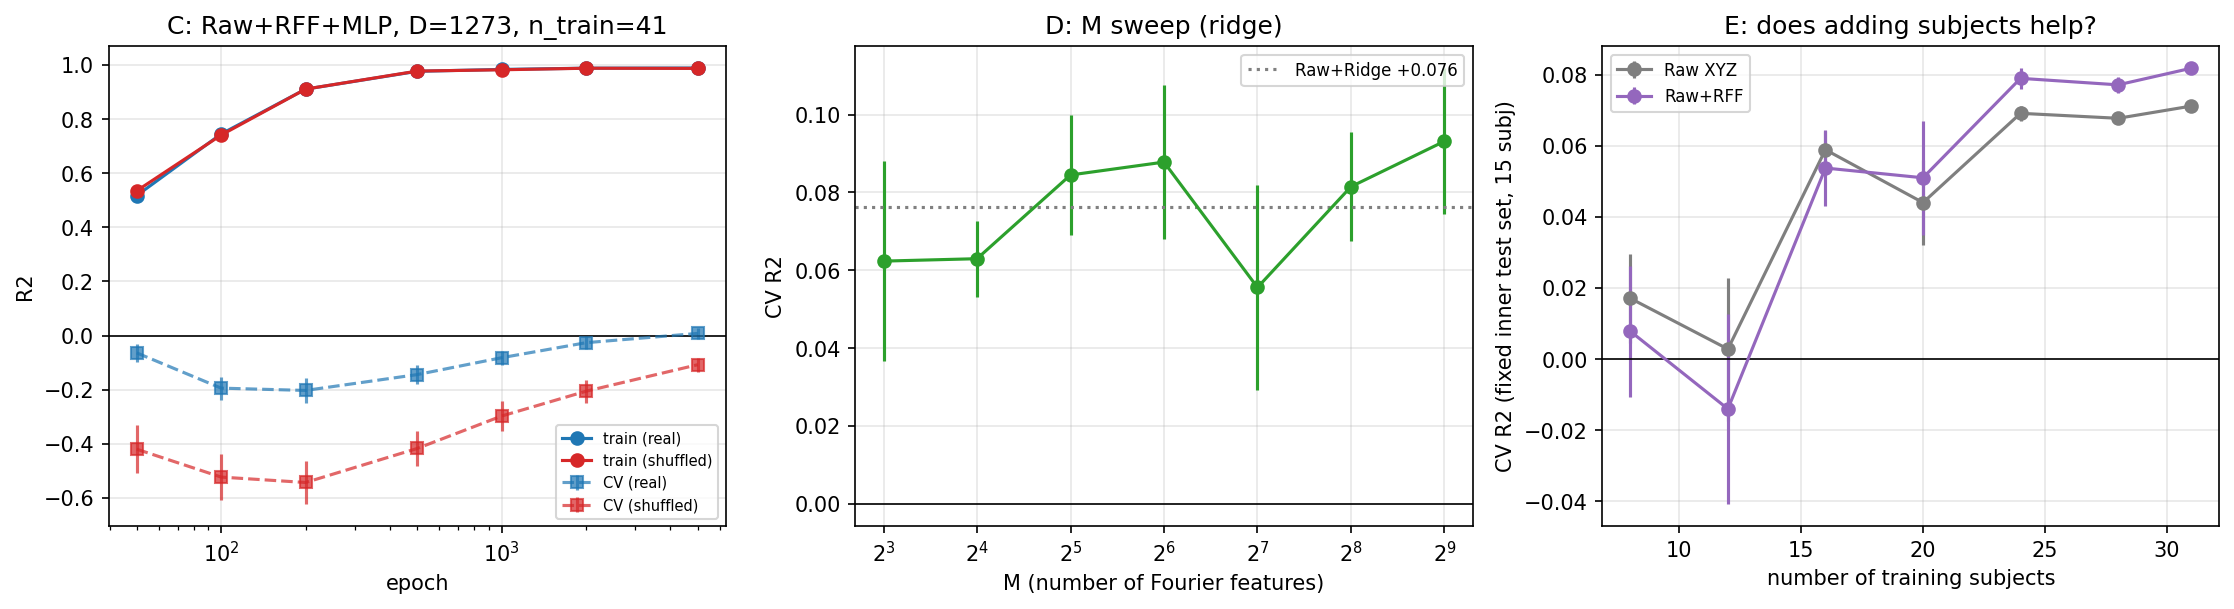

In [ ]:
# ==========================================================================
# Cell 8 — 三张图（给导师看的就是这三张）
# ==========================================================================
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))

# ---- (1) epoch 曲线 ---- (★ 图上一律用英文，中文字体在 Colab 上是豆腐块)
ep = CFG['CKPTS']
for key, cur, c in (('real', CURVE_REAL, 'tab:blue'), ('shuffled', CURVE_SHUF, 'tab:red')):
    tr = [cur[e][0].mean() for e in ep]
    cv = [cur[e][1].mean() for e in ep]
    se = [cur[e][1].std(ddof=1)/np.sqrt(len(cur[e][1])) for e in ep]
    ax[0].plot(ep, tr, '-o', color=c, label=f'train ({key})')
    ax[0].errorbar(ep, cv, yerr=se, fmt='--s', color=c, alpha=.7, label=f'CV ({key})')
ax[0].axhline(0, color='k', lw=.8)
ax[0].set_xscale('log'); ax[0].set_xlabel('epoch'); ax[0].set_ylabel('R2')
ax[0].set_title(f'C: Raw+RFF+MLP, D={X_RFF.shape[1]}, n_train={int(len(DEV)*.9)}')
ax[0].legend(fontsize=7); ax[0].grid(alpha=.3)

# ---- (2) M sweep ----
m = [r['M'] for r in SWEEP_M]
ax[1].errorbar(m, [r['cv'] for r in SWEEP_M], yerr=[r['sem'] for r in SWEEP_M],
               fmt='-o', color='tab:green')
ax[1].axhline(EXP_A['cv'], ls=':', color='gray', label=f"Raw+Ridge {EXP_A['cv']:+.3f}")
ax[1].axhline(0, color='k', lw=.8)
ax[1].set_xscale('log', base=2); ax[1].set_xlabel('M (number of Fourier features)')
ax[1].set_ylabel('CV R2'); ax[1].set_title('D: M sweep (ridge)')
ax[1].legend(fontsize=8); ax[1].grid(alpha=.3)

# ---- (3) 人数曲线 ----
nn = [c['n'] for c in NCURVE]
for k, c, lab in (('raw', 'tab:gray', 'Raw XYZ'), ('rff', 'tab:purple', 'Raw+RFF')):
    y = [x[k].mean() for x in NCURVE]
    s = [x[k].std(ddof=1)/np.sqrt(len(x[k])) for x in NCURVE]
    ax[2].errorbar(nn, y, yerr=s, fmt='-o', color=c, label=lab)
ax[2].axhline(0, color='k', lw=.8)
ax[2].set_xlabel('number of training subjects')
ax[2].set_ylabel('CV R2 (fixed inner test set, 15 subj)')
ax[2].set_title('E: does adding subjects help?')
ax[2].legend(fontsize=8); ax[2].grid(alpha=.3)

plt.tight_layout()
OUT_PNG = f'{SAVE_DIR}/FFM30_capacity_stress.png'
plt.savefig(OUT_PNG, dpi=150, bbox_inches='tight')
print('->', OUT_PNG)
try:
    from IPython.display import Image, display; display(Image(OUT_PNG))
except Exception:
    pass


In [ ]:
# ==========================================================================
# Learning curve — capacity stress test
# Requires: CURVE_REAL, CURVE_SHUF, CFG, X_RFF, SAVE_DIR
# ==========================================================================

import os
import numpy as np
import matplotlib.pyplot as plt

epochs = np.asarray(CFG["CKPTS"])
report_epoch = 5000  # pre-specified endpoint; do not select the best checkpoint afterward

def mean_sem(curve, epoch, which):
    values = np.asarray(curve[epoch][which], dtype=float)
    mean = values.mean()
    sem = values.std(ddof=1) / np.sqrt(len(values)) if len(values) > 1 else 0.0
    return mean, sem

real_train = np.array([mean_sem(CURVE_REAL, e, 0)[0] for e in epochs])
real_cv    = np.array([mean_sem(CURVE_REAL, e, 1)[0] for e in epochs])
real_sem   = np.array([mean_sem(CURVE_REAL, e, 1)[1] for e in epochs])

shuf_train = np.array([mean_sem(CURVE_SHUF, e, 0)[0] for e in epochs])
shuf_cv    = np.array([mean_sem(CURVE_SHUF, e, 1)[0] for e in epochs])
shuf_sem   = np.array([mean_sem(CURVE_SHUF, e, 1)[1] for e in epochs])

fig, ax = plt.subplots(figsize=(9, 5.5))

# Training fit: solid lines
ax.plot(epochs, real_train, "-o", lw=2.2, color="tab:blue",
        label="Train R² — real latent")
ax.plot(epochs, shuf_train, "-o", lw=2.2, color="tab:red",
        label="Train R² — shuffled latent")

# Unseen-subject CV: dashed lines with fold SEM
ax.errorbar(epochs, real_cv, yerr=real_sem, fmt="--s", capsize=4,
            lw=2.2, color="tab:blue", alpha=0.9,
            label="CV R² — real latent")
ax.errorbar(epochs, shuf_cv, yerr=shuf_sem, fmt="--s", capsize=4,
            lw=2.2, color="tab:red", alpha=0.9,
            label="CV R² — shuffled latent")

ax.axhline(0, color="black", lw=1, alpha=0.7)
ax.axvline(report_epoch, color="black", ls=":", lw=1.2,
           label=f"Pre-specified report endpoint: {report_epoch}")

ax.set_xscale("log")
ax.set_xticks(epochs)
ax.set_xticklabels([str(e) for e in epochs])
ax.set_xlabel("Training epochs")
ax.set_ylabel("R²")
ax.set_title(
    f"Capacity stress test: Raw XYZ + per-landmark RFF + MLP\n"
    f"D={X_RFF.shape[1]}, M={CFG['RFF_M']}, σ={CFG['RFF_SIGMA']}, "
    f"{CFG['N_FOLDS']}-fold CV"
)
ax.grid(alpha=0.25)
ax.legend(loc="best", fontsize=9)
plt.tight_layout()

out_png = os.path.join(SAVE_DIR, "FFM30_learning_curve.png")
plt.savefig(out_png, dpi=200, bbox_inches="tight")
plt.show()

# Fixed-endpoint summary: report this, not the best checkpoint.
i = list(epochs).index(report_epoch)
print(f"Saved: {out_png}")
print()
print(f"Epoch {report_epoch} (pre-specified endpoint)")
print(f"  Real target:     train R² = {real_train[i]:+.4f}, "
      f"CV R² = {real_cv[i]:+.4f} ± {real_sem[i]:.4f}")
print(f"  Shuffled target: train R² = {shuf_train[i]:+.4f}, "
      f"CV R² = {shuf_cv[i]:+.4f} ± {shuf_sem[i]:.4f}")

Saved: /content/drive/MyDrive/HRTF_Checkpoints/FFM30_learning_curve.png

Epoch 5000 (pre-specified endpoint)
  Real target:     train R² = +0.9895, CV R² = +0.0078 ± 0.0200
  Shuffled target: train R² = +0.9880, CV R² = -0.1080 ± 0.0257


In [ ]:
# ==========================================================================
# Cell 9 — 汇总 · 导出 · 写给导师的那段话
# ==========================================================================
tr_r, cv_r = CURVE_REAL[REPORT_EPOCH]
tr_s, cv_s = CURVE_SHUF[REPORT_EPOCH]

print(f"{'实验':<40}{'CV-R²':>10}{'±SEM':>8}{'train R²':>11}")
print('-' * 69)
print(f"{'A  Raw XYZ + Ridge':<40}{EXP_A['cv']:>+10.4f}{EXP_A['sem']:>8.4f}"
      f"{EXP_A['train']:>+11.4f}")
print(f"{'B  Raw + RFF + Ridge':<40}{EXP_B['cv']:>+10.4f}{EXP_B['sem']:>8.4f}"
      f"{EXP_B['train']:>+11.4f}")
print(f"{f'C  Raw + RFF + MLP ({REPORT_EPOCH} ep)':<40}{cv_r.mean():>+10.4f}"
      f"{cv_r.std(ddof=1)/np.sqrt(len(cv_r)):>8.4f}{tr_r.mean():>+11.4f}")
print(f"{f'   同上，目标打乱（负对照）':<40}{cv_s.mean():>+10.4f}"
      f"{cv_s.std(ddof=1)/np.sqrt(len(cv_s)):>8.4f}{tr_s.mean():>+11.4f}")
print('-' * 69)
print(f"D  M sweep {CFG['M_SWEEP']}: CV-R² 跨度 "
      f"{max(r['cv'] for r in SWEEP_M) - min(r['cv'] for r in SWEEP_M):.4f}")
print(f"E  人数曲线斜率 ≈ {_slope:+.5f} R²/人")

np.savez(f'{SAVE_DIR}/capacity_stress_v30.npz',
         ckpts=np.array(CFG['CKPTS']),
         curve_real_train=np.array([CURVE_REAL[e][0] for e in CFG['CKPTS']]),
         curve_real_cv=np.array([CURVE_REAL[e][1] for e in CFG['CKPTS']]),
         curve_shuf_train=np.array([CURVE_SHUF[e][0] for e in CFG['CKPTS']]),
         curve_shuf_cv=np.array([CURVE_SHUF[e][1] for e in CFG['CKPTS']]),
         sweep_M=np.array([r['M'] for r in SWEEP_M]),
         sweep_cv=np.array([r['cv'] for r in SWEEP_M]),
         ncurve_n=np.array(CFG['N_CURVE']),
         ncurve_rff=np.array([c['rff'] for c in NCURVE]),
         ncurve_raw=np.array([c['raw'] for c in NCURVE]),
         exp_a=EXP_A['cv'], exp_b=EXP_B['cv'],
         subject_hash=SUBJ_HASH, cfg=json.dumps(CFG, default=str))
print(f'\n-> {SAVE_DIR}/capacity_stress_v30.npz')

print(f"""
--------------------------------------------------------------------
写给导师 / 论文的那段话（把 X 换成实际数字）：

  With per-landmark Fourier features concatenated to the raw coordinates
  (D = {X_RFF.shape[1]}) and a high-capacity MLP trained for {REPORT_EPOCH} epochs to a
  training R² of {tr_r.mean():.3f}, cross-validated performance on unseen listeners
  remains at R² = {cv_r.mean():+.3f}. A label-permuted control reaches a comparable
  training fit ({tr_s.mean():.3f}), confirming that training-set fit is uninformative
  at D > N. This SUGGESTS the limiting factor is the information content of
  the sparse landmark set rather than the capacity of the regressor.

★ 用 suggests，不用 proves —— 你没有、也不可能穷举所有 architecture。
★ 这段话排除的是「训练不够 / 容量不够 / 基不够多」，
  它不排除「换 mesh 输入会不会更好」—— 那正是下一步。
--------------------------------------------------------------------""")


实验                                           CV-R²    ±SEM   train R²
---------------------------------------------------------------------
A  Raw XYZ + Ridge                         +0.0762  0.0138    +0.1268
B  Raw + RFF + Ridge                       +0.0845  0.0155    +0.2270
C  Raw + RFF + MLP (5000 ep)               +0.0078  0.0200    +0.9895
   同上，目标打乱（负对照）                            -0.1080  0.0257    +0.9880
---------------------------------------------------------------------
D  M sweep [8, 16, 32, 64, 128, 256, 512]: CV-R² 跨度 0.0375
E  人数曲线斜率 ≈ +0.00397 R²/人

-> /content/drive/MyDrive/HRTF_Checkpoints/capacity_stress_v30.npz

--------------------------------------------------------------------
写给导师 / 论文的那段话（把 X 换成实际数字）：

  With per-landmark Fourier features concatenated to the raw coordinates
  (D = 1273) and a high-capacity MLP trained for 5000 epochs to a
  training R² of 0.990, cross-validated performance on unseen listeners
  remains at R² = +0.008. A label-permuted contr

## 报数纪律（跑完对照一遍）

1. **报 epoch 5000，不报 7 个 checkpoint 里的最大值。** 后者是 7 次观测的最大值。
2. **train R² 不是证据。** 打乱对照的 train R² 和真实的一样高，就说明它不携带信息。
   论文里 train R² 只能和打乱对照并排出现，不能单独出现。
3. **每个数带作用域**：开发集 46 人（内部再切）、P=19、fold-local PCA、
   DC–15.85 kHz、`FFM26_best.pth`、σ={CFG.RFF_SIGMA}、M={CFG.RFF_M}。
4. **SEM 被低估**：10 折共享 90% 训练数据。写"CV 内部离散度"。
5. **test 的 15 人这个 notebook 没碰过。** 端到端 dB 的数在 FFM_2_9 的 Cell 7。

## 这个实验排除了什么、没排除什么

| 反驳 | 排除了吗 | 靠哪个 |
|---|---|---|
| 训练太短 | ✅ | C：5000 epoch 后 CV 仍不动 |
| 优化没收敛 | ✅ | C：train R² 已经饱和 |
| 网络容量不够 | ⚠️ 部分 | C，但 D>N 时 train R²→1 是必然，靠打乱对照才有意义 |
| Fourier 基太少 | ✅ | D：M 从 8 到 512 平坦 |
| Fourier 破坏了原始坐标 | ✅ | 输入是 [raw, RFF] 拼接 |
| σ 选坏了 | ✅ | 用的是 CV 选出来最有利的那组 |
| 人太少 | ❓ | **E 才回答这个**。斜率≈0 才叫信息上限 |
| 换个 architecture 就行 | ❌ | 穷举不了。措辞用 suggests |
| landmark 换成 mesh 会更好 | ❌ | 这是下一步，不是这个实验能回答的 |
